# Mission EdStats : analyser les indicateurs retenus et proposer une liste de pays (phase 3)

La phase précédente a réduit le tableau pays × indicateurs aux seuls indicateurs faiblement corrélés entre eux (`country_indicator_reduced.csv` dans `data/output/`).

**Objectif** : analyser chaque indicateur restant par pays et formuler une liste de pays pertinents pour l'implantation d'academy, en réponse à la demande de Mark.

Plan de ce notebook : présenter le tableau réduit (section 1), étudier la distribution de chaque indicateur (section 2), proposer une méthode quantitative de sélection des pays (section 3), conclure par la liste de pays proposée (section 4).

## 1. Présenter le tableau réduit

L'entrée de cette analyse est le CSV écrit par la phase précédente dans `data/output/` : `country_indicator_reduced.csv` (tableau pays × indicateurs réduits) et `EdStatsSeries.csv` (nom complet de chaque code d'indicateur).

### 1.1 Dossiers et lecture

`load_csv_output()` lit un CSV de `data/output/`, que le notebook soit lancé depuis la racine du projet ou depuis `notebooks/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_colwidth", None)  # show full indicator descriptions

candidates = [
    Path.cwd() / "data" / "output",         # from the project root
    Path.cwd() / ".." / "data" / "output",  # from notebooks/
]

OUTPUT_DIR = None
for candidate in candidates:
    if candidate.exists():
        OUTPUT_DIR = candidate.resolve()
        break
if OUTPUT_DIR is None:
    raise FileNotFoundError("data/output/ not found")

def load_csv_output(name, columns=None):
    """Read the CSV `name` from OUTPUT_DIR as is, optionally keeping only `columns`."""
    return pd.read_csv(OUTPUT_DIR / name, encoding="utf-8", usecols=columns)

OUTPUT_DIR

PosixPath('/Users/emmanuel/Formation Data Engineer/Projets/P2 - Analyse données systèmes éducatifs/data/output')

### 1.2 Le tableau réduit pays × indicateurs

Chargé une seule fois dans `reduced_table` et réutilisé par toutes les cellules suivantes : aucune opération ne modifie ce DataFrame en place, on recharge le CSV si besoin. Aperçu des 3 premières lignes :

In [2]:
# load once, reused by every cell of this notebook
reduced_table = load_csv_output("country_indicator_reduced.csv")
reduced_table.head(10)

,Country Code,Country Name,IT.NET.USER.P2,SP.SEC.UTOT.IN,SP.TER.TOTL.IN,SE.SEC.ENRR.UP,SE.TER.ENRR,PRJ.MYS.1519.MF,NY.GDP.PCAP.CD,SE.SEC.ENRL.TC.ZS,SE.XPD.TOTL.GD.ZS
0,ABW,Aruba,60.292077,4.478191e+03,6.799110e+03,90.496135,28.226781,8.259259,24357.132282,14.201038,5.872939
1,AFG,Afghanistan,4.332797,1.865566e+06,2.624559e+06,32.586328,4.899025,NaN,489.193612,35.668039,3.342328
2,AGO,Angola,5.180553,1.415692e+06,2.006447e+06,17.902200,6.445411,NaN,3483.189042,25.717081,3.100720
3,ALB,Albania,39.532074,1.980868e+05,2.749237e+05,78.346604,44.499039,8.792593,3833.464309,14.913130,3.289472
4,AND,Andorra,75.188177,NaN,NaN,NaN,NaN,NaN,40289.594889,7.972084,2.719720
5,ARE,United Arab Emirates,70.247694,2.328435e+05,3.399750e+05,NaN,NaN,9.540741,39984.323639,NaN,NaN
6,ARG,Argentina,43.902018,2.060006e+06,3.392539e+06,76.756416,73.124107,8.918519,10079.971248,14.431342,4.892109
7,ARM,Armenia,28.524414,1.163443e+05,2.789649e+05,89.769697,44.427286,8.940741,3142.616214,NaN,2.843909
8,ASM,American Samoa,NaN,NaN,NaN,NaN,NaN,NaN,10621.848286,NaN,NaN
9,ATG,Antigua and Barbuda,48.362707,3.069309e+03,7.225493e+03,84.146561,17.486815,NaN,12565.487532,11.937176,2.760067


Taille du tableau (lignes = pays, colonnes = `Country Code`, `Country Name` et les indicateurs) :

In [3]:
print(f"{reduced_table.shape[0]} rows, {reduced_table.shape[1]} columns")

214 rows, 11 columns


### 1.3 Les indicateurs retenus et leur signification

`EdStatsSeries.csv` associe chaque code (ex. `IT.NET.USER.P2`) à son nom officiel en anglais (`Indicator Name`, nom de l'indicateur). Sa colonne `Unit of measure` (unité de mesure) est vide pour ces 9 indicateurs : l'unité est donc notée explicitement ci-dessous, avec une courte description en français (dictionnaires modifiables). Tableau complet des indicateurs retenus :

In [4]:
# one short French description and unit per retained indicator code, editable
indicator_descriptions_fr = {
    "IT.NET.USER.P2": "Utilisateurs d'Internet (usage au cours des 3 derniers mois)",
    "SP.SEC.UTOT.IN": "Population d'âge théorique du secondaire supérieur",
    "SP.TER.TOTL.IN": "Population d'âge théorique du supérieur",
    "SE.SEC.ENRR.UP": "Taux brut de scolarisation dans le secondaire supérieur",
    "SE.TER.ENRR": "Taux brut de scolarisation dans le supérieur",
    "PRJ.MYS.1519.MF": "Nombre moyen d'années de scolarité des 15-19 ans (projection)",
    "NY.GDP.PCAP.CD": "Produit intérieur brut par habitant",
    "SE.SEC.ENRL.TC.ZS": "Nombre moyen d'élèves par enseignant dans le secondaire",
    "SE.XPD.TOTL.GD.ZS": "Dépenses publiques totales d'éducation",
}
indicator_units = {
    "IT.NET.USER.P2": "% (pour 100 habitants)",
    "SP.SEC.UTOT.IN": "personnes (nombre)",
    "SP.TER.TOTL.IN": "personnes (nombre)",
    "SE.SEC.ENRR.UP": "%",
    "SE.TER.ENRR": "%",
    "PRJ.MYS.1519.MF": "années",
    "NY.GDP.PCAP.CD": "$ US courants / habitant",
    "SE.SEC.ENRL.TC.ZS": "élèves / enseignant",
    "SE.XPD.TOTL.GD.ZS": "% du PIB",
}

indicator_columns = []
for col in reduced_table.columns:
    if col not in ("Country Code", "Country Name"):
        indicator_columns.append(col)

# load once, reused later for indicator names
series = load_csv_output("EdStatsSeries.csv", columns=["Series Code", "Indicator Name"])
series = series[series["Series Code"].isin(indicator_columns)]

# full table: code, official English name, unit, French description
rows = []
for code in indicator_columns:
    name = series.loc[series["Series Code"] == code, "Indicator Name"].iloc[0]
    rows.append({"Code": code, "Indicator Name": name, "Unité": indicator_units[code],
                 "Description (français)": indicator_descriptions_fr[code]})
indicators = pd.DataFrame(rows)
indicators

,Code,Indicator Name,Unité,Description (français)
0,IT.NET.USER.P2,Internet users (per 100 people),% (pour 100 habitants),Utilisateurs d'Internet (usage au cours des 3 derniers mois)
1,SP.SEC.UTOT.IN,"Population of the official age for upper secondary education, both sexes (number)",personnes (nombre),Population d'âge théorique du secondaire supérieur
2,SP.TER.TOTL.IN,"Population of the official age for tertiary education, both sexes (number)",personnes (nombre),Population d'âge théorique du supérieur
3,SE.SEC.ENRR.UP,"Gross enrolment ratio, upper secondary, both sexes (%)",%,Taux brut de scolarisation dans le secondaire supérieur
4,SE.TER.ENRR,"Gross enrolment ratio, tertiary, both sexes (%)",%,Taux brut de scolarisation dans le supérieur
5,PRJ.MYS.1519.MF,Projection: Mean years of schooling. Age 15-19. Total,années,Nombre moyen d'années de scolarité des 15-19 ans (projection)
6,NY.GDP.PCAP.CD,GDP per capita (current US$),$ US courants / habitant,Produit intérieur brut par habitant
7,SE.SEC.ENRL.TC.ZS,Pupil-teacher ratio in secondary education (headcount basis),élèves / enseignant,Nombre moyen d'élèves par enseignant dans le secondaire
8,SE.XPD.TOTL.GD.ZS,Government expenditure on education as % of GDP (%),% du PIB,Dépenses publiques totales d'éducation


### Bilan de la section 1

Tableau réduit chargé une seule fois depuis `data/output/` (`country_indicator_reduced.csv`), taille affichée, et pour chaque indicateur retenu : nom officiel (`EdStatsSeries.csv`), unité et description en français.

## 2. Statistiques descriptives et distributions

`describe()` et `displot()` pour chacun des 9 indicateurs, via une fonction et une boucle `for`, suivis de l'interprétation de chaque graphique.

### 2.1 Toutes les distributions : fonction + boucle `for`

`describe()` (statistiques descriptives) et `displot()` (distribution) packagés dans `describe_indicator()` et appliqués aux 9 indicateurs par une boucle `for`. `displot()` trace la distribution empirique (empirical distribution) des pays renseignés (manquantes écartées) : axe X = valeur de l'indicateur, axe Y = nombre de pays ; `kde=True` lisse la forme.

IT.NET.USER.P2: 205 countries with data out of 214, 9 missing
count    205.000000
mean      34.520596
std       25.710480
min        0.000000
25%       10.719944
50%       31.043486
75%       53.220820
max       92.397466
Name: IT.NET.USER.P2, dtype: float64


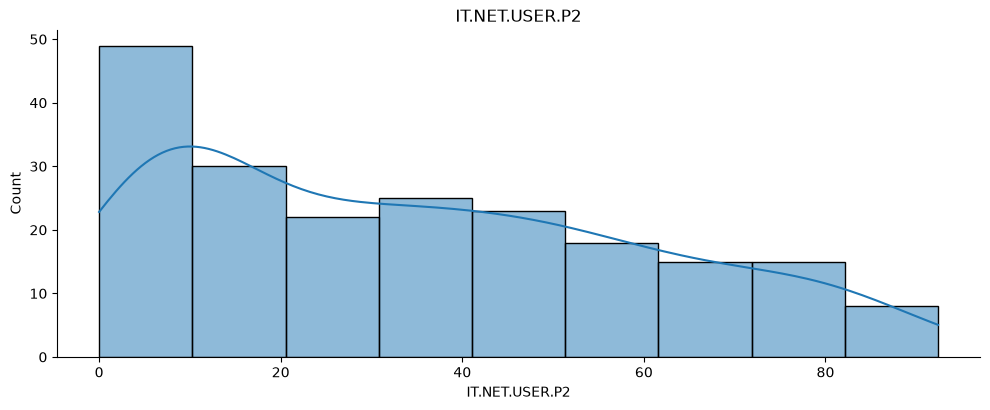

SP.SEC.UTOT.IN: 197 countries with data out of 214, 17 missing
count    1.970000e+02
mean     1.969780e+06
std      8.347960e+06
min      4.015809e+02
25%      7.983000e+04
50%      3.440864e+05
75%      1.302625e+06
max      9.610320e+07
Name: SP.SEC.UTOT.IN, dtype: float64


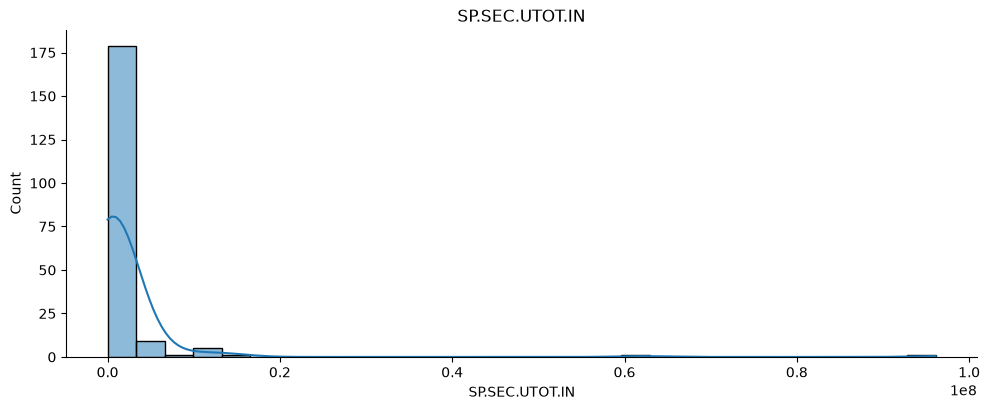

SP.TER.TOTL.IN: 198 countries with data out of 214, 16 missing
count    1.980000e+02
mean     3.012970e+06
std      1.184545e+07
min      9.385309e+02
25%      1.347557e+05
50%      6.021755e+05
75%      2.003482e+06
max      1.149028e+08
Name: SP.TER.TOTL.IN, dtype: float64


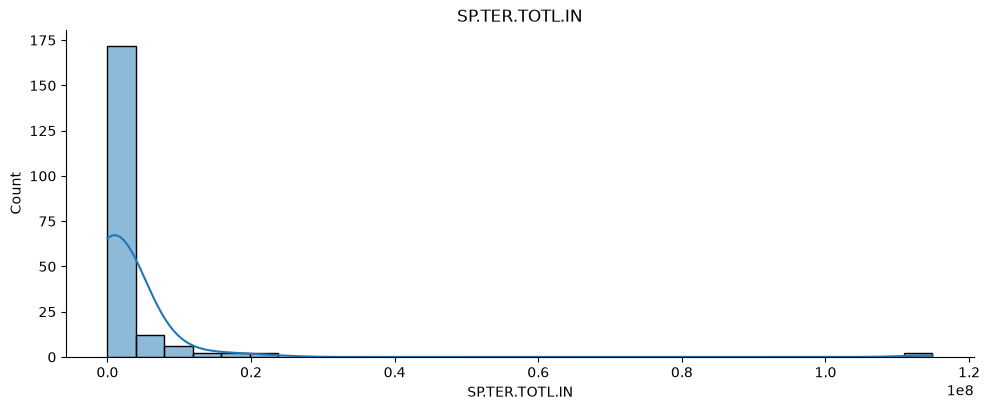

SE.SEC.ENRR.UP: 191 countries with data out of 214, 23 missing
count    191.000000
mean      68.747228
std       34.169576
min        4.846744
25%       35.450581
50%       75.457953
75%       92.159979
max      181.812956
Name: SE.SEC.ENRR.UP, dtype: float64


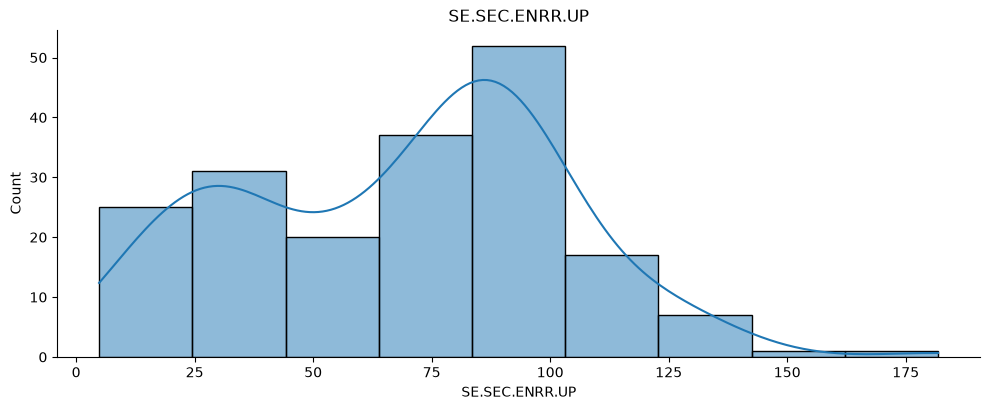

SE.TER.ENRR: 184 countries with data out of 214, 30 missing
count    184.000000
mean      33.805279
std       26.108940
min        0.570240
25%        9.704846
50%       28.421866
75%       56.821795
max       99.173149
Name: SE.TER.ENRR, dtype: float64


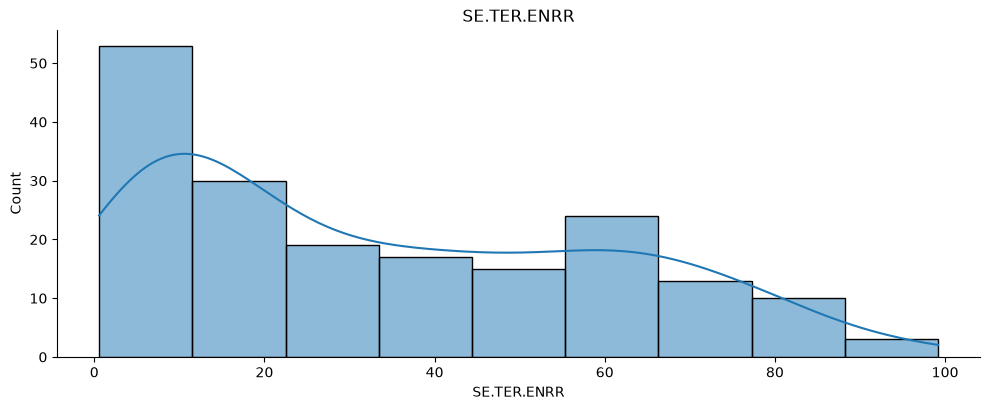

PRJ.MYS.1519.MF: 166 countries with data out of 214, 48 missing
count    166.000000
mean       8.237751
std        2.099124
min        2.177778
25%        6.905556
50%        8.909259
75%        9.559259
max       12.359259
Name: PRJ.MYS.1519.MF, dtype: float64


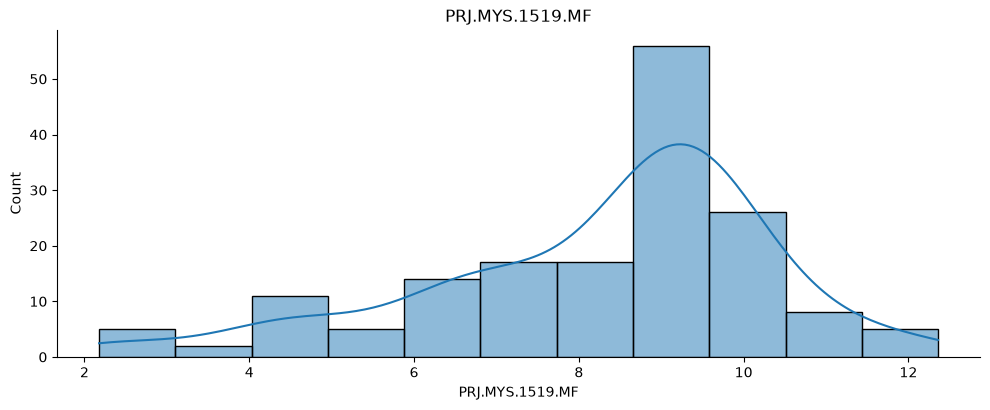

NY.GDP.PCAP.CD: 207 countries with data out of 214, 7 missing
count       207.000000
mean      15407.699170
std       23148.607571
min         232.969457
25%        1465.952332
50%        5343.979118
75%       18007.844942
max      146492.649110
Name: NY.GDP.PCAP.CD, dtype: float64


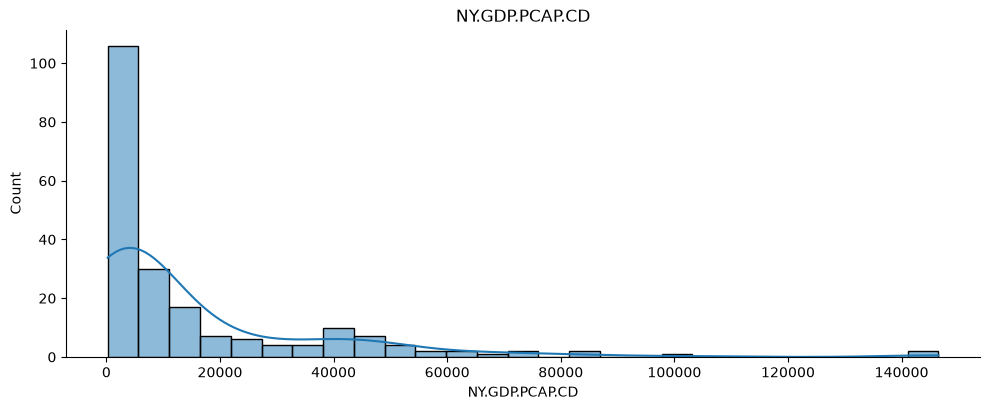

SE.SEC.ENRL.TC.ZS: 182 countries with data out of 214, 32 missing
count    182.000000
mean      17.772646
std        8.855730
min        6.024375
25%       11.021086
50%       15.422787
75%       22.488417
max       71.086785
Name: SE.SEC.ENRL.TC.ZS, dtype: float64


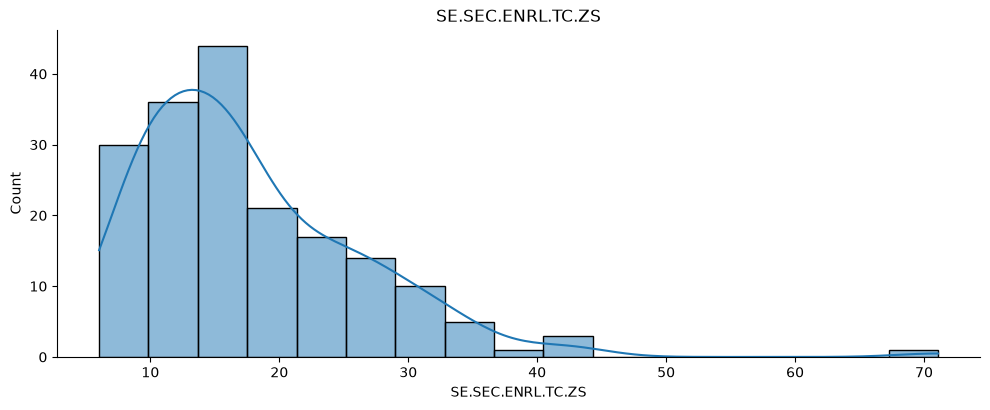

SE.XPD.TOTL.GD.ZS: 182 countries with data out of 214, 32 missing
count    182.000000
mean       4.619431
std        1.974531
min        1.342306
25%        3.145925
50%        4.425118
75%        5.569804
max       12.128951
Name: SE.XPD.TOTL.GD.ZS, dtype: float64


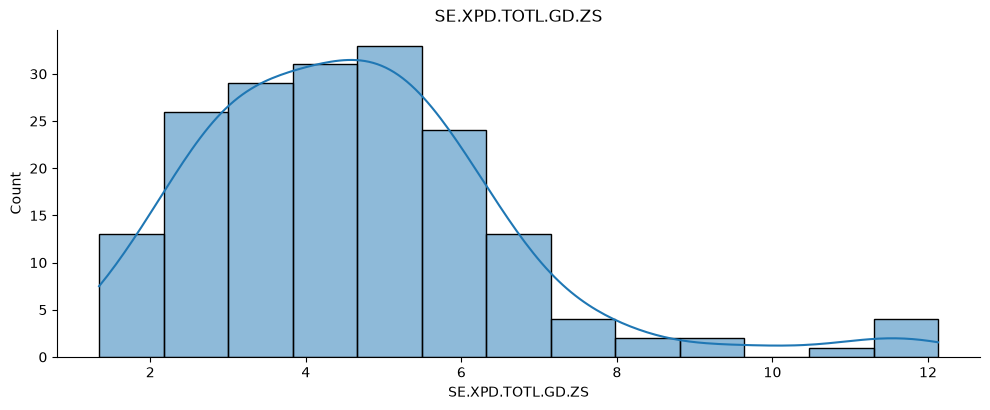

In [5]:
def describe_indicator(table, indicator):
    """Print the descriptive stats and the distribution plot of one indicator."""
    values = table[indicator].dropna()
    missing = table[indicator].isna().sum()
    print(f"{indicator}: {len(values)} countries with data out of {len(table)}, {missing} missing")
    print(values.describe())
    sns.displot(values, kde=True, height=4, aspect=2.5)
    plt.title(indicator)
    plt.show()

for indicator in indicator_columns:
    describe_indicator(reduced_table, indicator)

#### `IT.NET.USER.P2` — utilisateurs d'Internet pour 100 habitants

Distribution asymétrique à droite (moyenne 34,5 % > médiane 31 %) : la plupart des pays ont peu d'internautes, et quelques pays très connectés étirent la courbe vers la droite. 9 pays sur 214 sans donnée.

#### `SP.SEC.UTOT.IN` — population d'âge du secondaire supérieur

Distribution très asymétrique à droite (moyenne 1,97 million > médiane 344 000 habitants) : la plupart des pays ont peu d'habitants en âge du secondaire supérieur, et quelques pays très peuplés (min 402, max 96,1 millions) étirent la courbe vers la droite. 17 pays sur 214 sans donnée.

#### `SP.TER.TOTL.IN` — population d'âge du supérieur

Distribution très asymétrique à droite (moyenne 3,01 millions > médiane 602 000 habitants) : la plupart des pays ont peu d'habitants en âge du supérieur, et quelques pays très peuplés (min 939, max 114,9 millions) étirent la courbe vers la droite. 16 pays sur 214 sans donnée.

#### `SE.SEC.ENRR.UP` — taux brut de scolarisation, secondaire supérieur

Distribution asymétrique à gauche (moyenne 68,7 % < médiane 75,5 %) : la plupart des pays ont un taux de scolarisation élevé au secondaire supérieur, et quelques pays à très faible taux (min 4,8 %) étirent la courbe vers la gauche, avec un max à 181,8 %. 23 pays sur 214 sans donnée.

Un taux brut peut dépasser 100 % : il rapporte tous les inscrits au secondaire supérieur, quel que soit leur âge (redoublants compris), à la population ayant l'âge officiel de ce niveau.

#### `SE.TER.ENRR` — taux brut de scolarisation, supérieur

Distribution asymétrique à droite (moyenne 33,8 % > médiane 28,4 %) : la plupart des pays ont peu d'inscrits dans le supérieur, et quelques pays très scolarisés (min 0,6 %, max 99,2 %) étirent la courbe vers la droite. 30 pays sur 214 sans donnée.

#### `PRJ.MYS.1519.MF` — années de scolarité projetées des 15-19 ans

Distribution asymétrique à gauche (moyenne 8,2 ans < médiane 8,9 ans) : la plupart des pays prévoient environ 9 ans de scolarité pour les 15-19 ans, et quelques pays à très faible niveau (min 2,2 ans) étirent la courbe vers la gauche, avec un max à 12,4 ans. 48 pays sur 214 sans donnée.

#### `NY.GDP.PCAP.CD` — PIB par habitant

Distribution très asymétrique à droite (moyenne 15 408 USD > médiane 5 344 USD) : la plupart des pays ont un PIB par habitant modeste, et quelques pays très riches (min 233 USD, max 146 493 USD) étirent la courbe vers la droite. 7 pays sur 214 sans donnée.

#### `SE.SEC.ENRL.TC.ZS` — élèves par enseignant au secondaire

Distribution asymétrique à droite (moyenne 17,8 élèves par enseignant > médiane 15,4) : la plupart des pays ont environ 15 élèves par enseignant au secondaire, et quelques pays très chargés (min 6,0, max 71,1) étirent la courbe vers la droite. 32 pays sur 214 sans donnée.

#### `SE.XPD.TOTL.GD.ZS` — dépenses publiques d'éducation en % du PIB

Distribution légèrement asymétrique à droite (moyenne 4,6 % > médiane 4,4 % du PIB) : la plupart des pays consacrent environ 4 à 5 % de leur PIB à l'éducation, et quelques pays en dépensent beaucoup plus (min 1,3 %, max 12,1 %). 32 pays sur 214 sans donnée.

### Bilan de la section 2

Chaque indicateur renseigne entre 166 et 207 pays sur 214, donc les comparaisons pays à pays sont possibles. La plupart des distributions sont asymétriques à droite (moyenne > médiane), étirées par quelques pays extrêmes. Les effectifs bruts (population du secondaire supérieur, du supérieur) varient avec la taille du pays, tandis que les taux en % et les ratios (PIB par habitant, élèves par enseignant, dépenses d'éducation) se comparent directement d'un pays à l'autre.